In [49]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [50]:
# 데이터가져오기
# 데이터 전처리
# 데이터 분리
# PolynomialFeatures 추가
# degree 추가
# 정규화작업 

#### 데이터 학습
# 규제 적용 후 데이터 학습
# alpha 값 변경 후 데이터 학습 확인 

# 데이터 예측
# 정확도 

In [51]:
df = pd.read_csv('data/perch_full.csv')
df.head(5)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43
3,16.2,4.59,2.63
4,17.4,4.59,2.94


In [52]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
1000.0, 1000.0]

In [53]:
df.shape

(56, 3)

In [54]:
len(perch_weight)

56

In [55]:
train_data, test_data, train_label, test_label = train_test_split(df,perch_weight,random_state=42)
# train_data, test_data, train_label, test_label = train_test_split(df,perch_weight,random_state=42)


In [56]:
poly = PolynomialFeatures(degree=15,include_bias=False)
poly.fit([[2,3]])
train_poly = poly.transform([[2,3]])
train_poly

array([[2.0000000e+00, 3.0000000e+00, 4.0000000e+00, 6.0000000e+00,
        9.0000000e+00, 8.0000000e+00, 1.2000000e+01, 1.8000000e+01,
        2.7000000e+01, 1.6000000e+01, 2.4000000e+01, 3.6000000e+01,
        5.4000000e+01, 8.1000000e+01, 3.2000000e+01, 4.8000000e+01,
        7.2000000e+01, 1.0800000e+02, 1.6200000e+02, 2.4300000e+02,
        6.4000000e+01, 9.6000000e+01, 1.4400000e+02, 2.1600000e+02,
        3.2400000e+02, 4.8600000e+02, 7.2900000e+02, 1.2800000e+02,
        1.9200000e+02, 2.8800000e+02, 4.3200000e+02, 6.4800000e+02,
        9.7200000e+02, 1.4580000e+03, 2.1870000e+03, 2.5600000e+02,
        3.8400000e+02, 5.7600000e+02, 8.6400000e+02, 1.2960000e+03,
        1.9440000e+03, 2.9160000e+03, 4.3740000e+03, 6.5610000e+03,
        5.1200000e+02, 7.6800000e+02, 1.1520000e+03, 1.7280000e+03,
        2.5920000e+03, 3.8880000e+03, 5.8320000e+03, 8.7480000e+03,
        1.3122000e+04, 1.9683000e+04, 1.0240000e+03, 1.5360000e+03,
        2.3040000e+03, 3.4560000e+03, 5.1840000e

In [57]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
# test_poly[:5]
print(test_poly.shape)

(14, 815)


In [58]:
train_data[:5]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52
6,18.7,5.20,3.12
4,17.4,4.59,2.94
41,36.0,10.61,6.74


In [59]:
ss = StandardScaler()

ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [60]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(train_poly)
print('예측 :', predict)

score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train 정확도:', score)
print('test 정확도:', score2)

예측 : [ 152.77043936  153.32728514  152.79704337  152.70584263  654.06869499
  151.876932    953.30610594  913.39482345 1016.76251918  153.13251476
  152.57378748  153.45332826  154.80271657  156.17321465 1110.85098423
 1019.76697039  154.26098287  153.08484658  153.99733641  866.66313452
  344.44474417  156.91688533  715.52746957  152.64771738  153.4785463
  152.65355184  601.32632684  840.55724216  164.01879018  153.91103675
  676.65259061  153.27772673  151.35607394  153.89137631  967.19638535
  153.94960838  152.81187656  578.7380299   153.26372335  156.02424177
 1092.35905358  480.22750021]
train 정확도: 0.9549039586533028
test 정확도: 0.11237909801910873


In [61]:
print(poly.get_feature_names_out())

['length' ' height' ' width' 'length^2' 'length  height' 'length  width'
 ' height^2' ' height  width' ' width^2' 'length^3' 'length^2  height'
 'length^2  width' 'length  height^2' 'length  height  width'
 'length  width^2' ' height^3' ' height^2  width' ' height  width^2'
 ' width^3' 'length^4' 'length^3  height' 'length^3  width'
 'length^2  height^2' 'length^2  height  width' 'length^2  width^2'
 'length  height^3' 'length  height^2  width' 'length  height  width^2'
 'length  width^3' ' height^4' ' height^3  width' ' height^2  width^2'
 ' height  width^3' ' width^4' 'length^5' 'length^4  height'
 'length^4  width' 'length^3  height^2' 'length^3  height  width'
 'length^3  width^2' 'length^2  height^3' 'length^2  height^2  width'
 'length^2  height  width^2' 'length^2  width^3' 'length  height^4'
 'length  height^3  width' 'length  height^2  width^2'
 'length  height  width^3' 'length  width^4' ' height^5'
 ' height^4  width' ' height^3  width^2' ' height^2  width^3'
 ' height  widt

In [62]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list: 
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)

    train_score.append(score)
    test_score.append(score2)

print('완료')


완료


In [63]:
print('train 정확도:', score)
print('test 정확도:', score2)

train 정확도: 0.9842356838386997
test 정확도: 0.9832356926414059


In [64]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

print('train 정확도 :', score)
print('test 정확도 :', score2) 

train 정확도 : 0.9842356838386997
test 정확도 : 0.9832356926414059


C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_1528\3810178061.py:5: UserWarning: Mismatched number of handles and labels: len(handles) = 5 len(labels) = 4
  plt.legend('Train','Test')
C:\Users\Public\Documents\ESTsoft\CreatorTemp\ipykernel_1528\3810178061.py:5: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend('Train','Test')


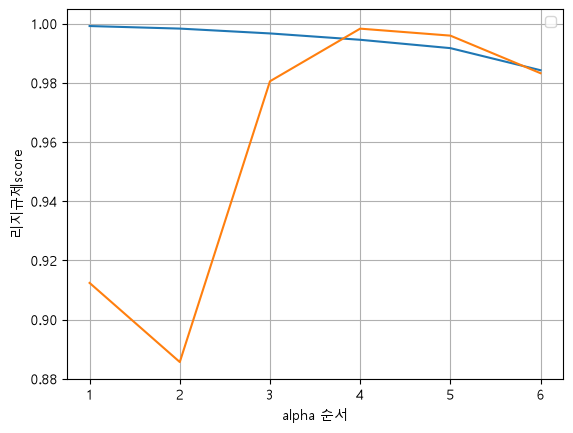

In [65]:
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.legend('Train','Test')
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.show()